# Linear version of Reasoning-aware 3PL

In [1]:
## CONFIG
GH_NODES = 200
MAX_ITER = 200
MU_GAMMA = 0.1
MU_KAPPA = -0.01
KAPPA_MAX=-0.00001

OPTIMAL_KAPPA_INIT = True 

RIDGE_KAPPA = 0.1
RIDGE_GAMMA = 0.1
RIDGE_B = 0.1
RIDGE_A = 0.5
RIDGE_X0 = 1000

strict_Y_int = False

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

# Graphical configs
# 1. Reset seaborn to baseline
sns.set_style('whitegrid')
sns.set_context('paper') # Remove font_scale!

# 2. Hardcode the absolute font sizes for publication
plt.rcParams.update({
    'font.size': 9,             # Global baseline
    'figure.titlesize': 9,      # Global figure titles (Added)
    'axes.titlesize': 10,       # Title of the subplot (ax.set_title)
    'axes.labelsize': 9,        # X and Y axis labels
    'xtick.labelsize': 8,       # Numbers on the X axis
    'ytick.labelsize': 8,       # Numbers on the Y axis
    'legend.fontsize': 8,       # Legend text
    'legend.title_fontsize': 8  # Legend title
})

### Data loading

In [3]:
B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [4]:
B = pd.concat([B_language, B_coding, B_reasoning, B_math],axis=0)
Y = pd.concat([Y_language, Y_coding, Y_reasoning, Y_math],axis=0)
c = pd.concat([c_language, c_coding, c_reasoning, c_math],axis=0)

In [5]:
from reasoning_aware_irt.livebench_utils import reindex
_ = reindex(Y, B, c) # little helper to make sure that all dataframes have exactly the same sorted question_id indices

the model_id Y/B sequence is great!!
the question_id Y/B sequence is great!!
the question_id Y/c sequence is great!!


In [6]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:5])

(786, 42) (786, 42)
0.39359059581389527 1310.9940930570701
(786,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02]


In [7]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


In [8]:
x0_j = np.log1p(B_ij.mean(axis=0)) # budget regularizer (Eq.12 in the paper)

# Evaluate with Reasoning-Aware 3PL's GEM : Linear Version

In [9]:
from reasoning_aware_irt.gem_quad import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem_quad import ReasoningAware3PLQuadraticCalibrator as ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)
cfg = CalibrationConfig()
cfg # lets see the default config


CalibrationConfig(gh_nodes=17, max_iter=50, tol=0.0001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=False, tau=0.75, ridge_a=0.001, ridge_b=0.001, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.2, mu_kappa=-0.02, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-06, x0_j=None, ridge_x0=0.1)

In [10]:
%%time
init_param_dict = None
    
cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT,
use_quadratic=False # ENABLE linear mode here
)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=False, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.1, mu_kappa=-0.01, a_min=0.05, a_max=5.0, gamma_min=-0.5, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([6.35004162, 7.18324597, 6.22199298, 6.10262406, 6.08033779,
       6.31970369, 6.66785474, 5.85850006, 6.37936752, 6.09960554,
       5.78765811, 5.83985728, 5.87082677, 6.04222478, 5.90920246,
       5.76998548, 6.39809522, 6.28766226, 6.65008317, 7.12763448,
       5.98803629, 6.62097526, 5.86790868, 5.80626863, 5.67414051,
       6.33643609, 5.74972923, 6.22767251, 6.46911815, 6.46083781,
       6.523779  , 6.19990512, 5.95793145, 6.17126225, 8.08663221,
       7.75749563, 8.41777231, 8.89141742, 9.26252837, 8.86775312,
       7.09789816, 6.60762969]), ridge_x0=1000)
CPU times: user 725 μs, sys: 0 ns, total: 725 μs
Wall time: 

In [11]:

fit_results = calibrator.fit(data, strict_Y_int=strict_Y_int, init_param_dict=init_param_dict)

iter   1  ll=-15062.013825   dLL=nan
iter   2  ll=-13907.349267   dLL=nan
iter   3  ll=-13853.638699   dLL=5.371e+01
iter   4  ll=-13830.701707   dLL=2.294e+01
iter   5  ll=-13819.896727   dLL=1.080e+01
iter   6  ll=-13814.846768   dLL=5.050e+00
iter   7  ll=-13811.207552   dLL=3.639e+00
iter   8  ll=-13808.677235   dLL=2.530e+00
iter   9  ll=-13808.301895   dLL=3.753e-01
iter  10  ll=-13807.500489   dLL=8.014e-01
iter  11  ll=-13805.750757   dLL=1.750e+00
iter  12  ll=-13805.988679   dLL=-2.379e-01
iter  13  ll=-13806.868009   dLL=-8.793e-01
iter  14  ll=-13807.371111   dLL=-5.031e-01
iter  15  ll=-13807.452079   dLL=-8.097e-02
iter  16  ll=-13807.244579   dLL=2.075e-01
iter  17  ll=-13807.060363   dLL=1.842e-01
iter  18  ll=-13806.936624   dLL=1.237e-01
iter  19  ll=-13806.609471   dLL=3.272e-01
iter  20  ll=-13806.455678   dLL=1.538e-01
iter  21  ll=-13806.295884   dLL=1.598e-01
iter  22  ll=-13806.124650   dLL=1.712e-01
iter  23  ll=-13806.071652   dLL=5.300e-02
iter  24  ll=-13806

In [12]:
fit_results.info['c_i'] = c_i
fit_results.info['B_ij'] = B_ij

# Explore Output
Since this is a linear model, $\kappa = 0$ and there is no optimal theta (an ability always increases if a budget increases)

In [13]:
from reasoning_aware_irt.posthoc import print_model_summary
data2 = print_model_summary(model_list, fit_results, Y_ij, sort_by="best_theta")

Meta-Llama-3.1-405B-Instruct-Turbo  | BaseTheta:   0.10 ± 0.055| Gamma: -0.0157 ± 0.0695| Kappa: -0.0000 ± nan |Avg Y :   0.456
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -0.000 ±     nan|

Meta-Llama-3.1-70B-Instruct-Turbo   | BaseTheta:  -0.33 ± 0.061| Gamma: -0.0104 ± 0.0378| Kappa: -0.0000 ± nan |Avg Y :   0.402
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -0.406 ±     nan|

Phi-3-medium-128k-instruct          | BaseTheta:  -1.72 ± 0.124| Gamma: -0.0013 ± 0.0920| Kappa: -0.0000 ± nan |Avg Y :   0.238
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -1.724 ±     nan|

Phi-3-medium-4k-instruct            | BaseTheta:  -1.58 ± 0.123| Gamma: -0.0041 ± 0.0978| Kappa: -0.0000 ± nan |Avg Y :   0.251
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -1.609 ±     nan|

Phi-3-mini-128k-instruct            | BaseTheta:  -2.38 ± 0.142| Gamma: -0.0058 ± 0.0967| Kappa: -0.0000 ± nan |Avg Y :   0.190
Best Budget:   nan|BestTheta

## Visualization with Empirical Bins

In [15]:
from reasoning_aware_irt.utils import align_theta_scales

cpath = "data/calibration_classic.pkl"
classic_results = joblib.load(cpath)
theta_classic_orig = classic_results.theta_j_mean
print(theta_classic_orig.shape)

(43,)


In [ ]:
gamma_j=fit_results.gamma_j
kappa_j=fit_results.kappa_j
theta_base=fit_results.theta_j_mean

x_star = np.log1p(B_ij.max(axis=0))
print(x_star.shape)

theta_max = theta_base + gamma_j * x_star
print(x_star.shape, theta_max.shape)
print(theta_classic_orig.mean(), theta_classic_orig.std())
print(theta_max.mean(), theta_max.std())

theta_classic = align_theta_scales(theta_classic_orig, theta_max)
print(theta_classic.mean(), theta_classic.std())

(42,)
(42,) (42,)
-0.7022631495327021 1.5838400538214659
-0.5390655178515684 1.2407941907420565
-0.5390655178515684 1.2407941907420565


In [21]:
fit_results.gamma_j

array([-0.01567221, -0.01044954, -0.00131778, -0.00412709, -0.00580899,
       -0.007405  , -0.00502519, -0.0080646 ,  0.00344195, -0.00693727,
       -0.02270941, -0.00351967, -0.00661344, -0.00380463, -0.00521987,
       -0.00909225, -0.01130742,  0.00664246, -0.02032776, -0.03979818,
       -0.01063118, -0.00574157, -0.00640944, -0.00268301, -0.01030483,
       -0.01907957, -0.00747226, -0.02758876, -0.01619416, -0.02397559,
       -0.02297116, -0.00043934, -0.00829625, -0.01343517,  0.03483709,
        0.01075251, -0.00166249, -0.00404686,  0.01672177,  0.00139724,
       -0.00782494,  0.00987057])

/workspaces/reasoning-aware-irt/reasoning_aware_irt/utils.py:1017: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=figsize)


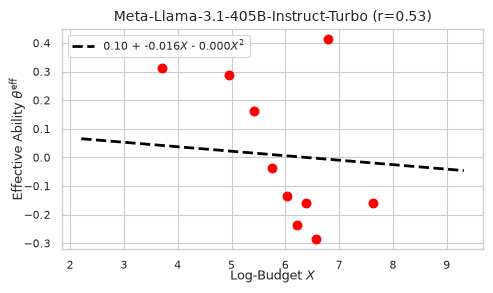

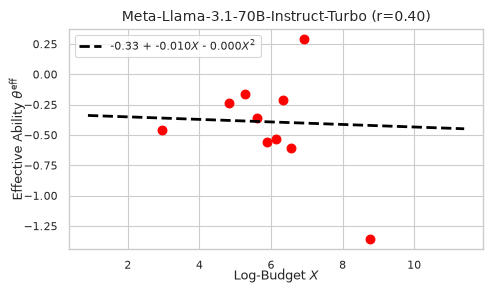

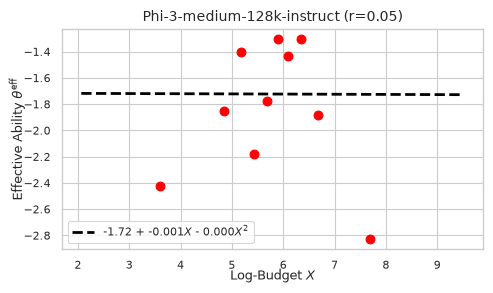

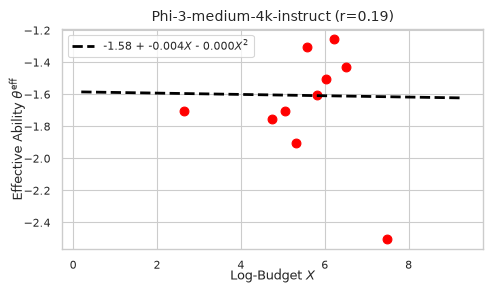

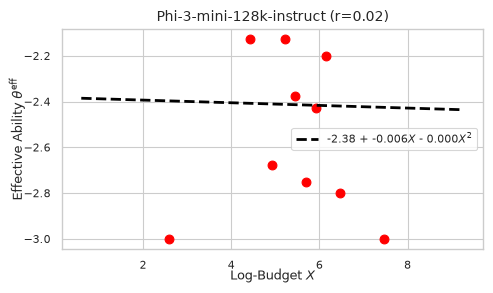

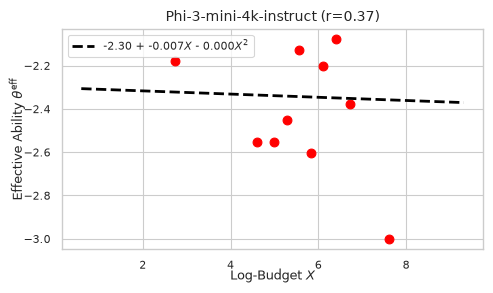

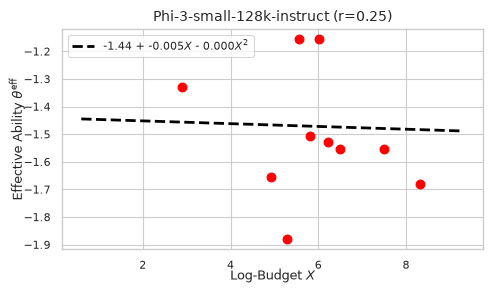

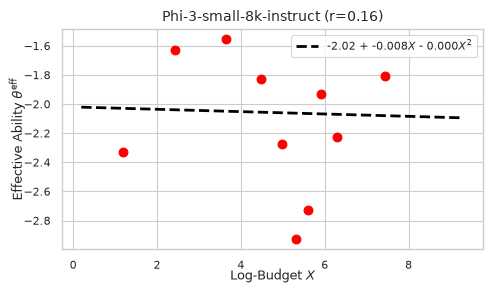

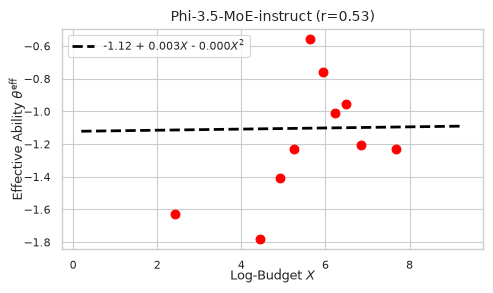

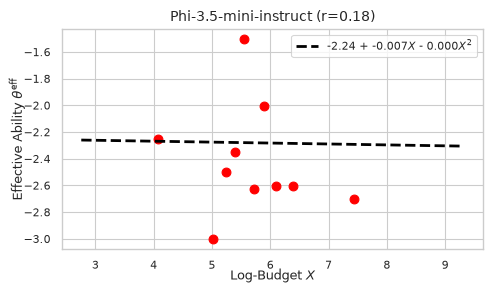

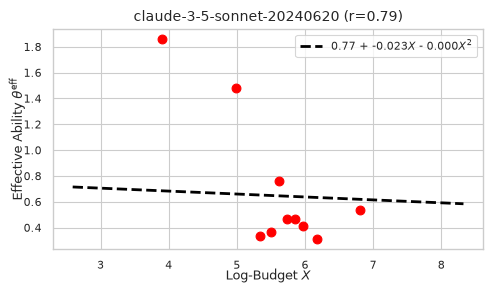

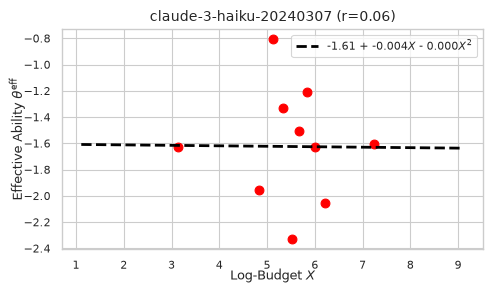

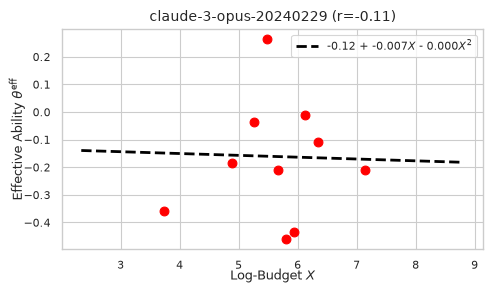

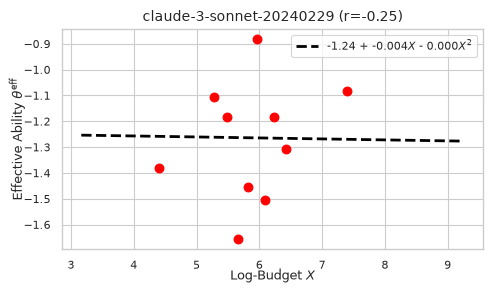

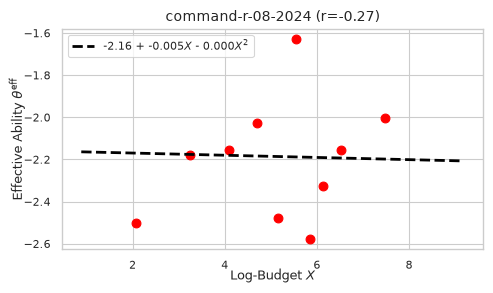

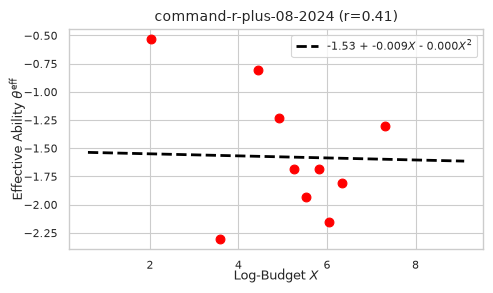

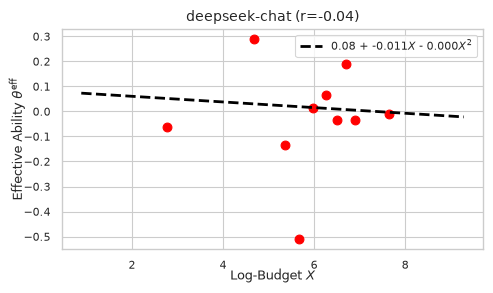

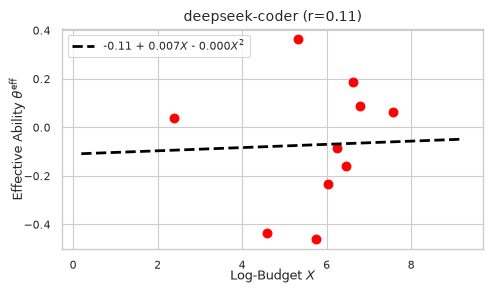

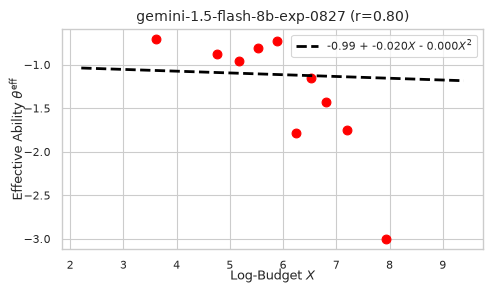

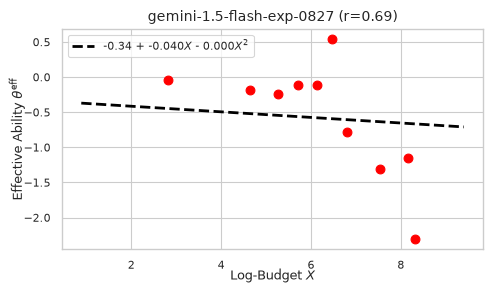

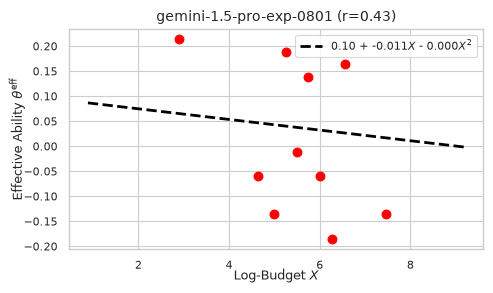

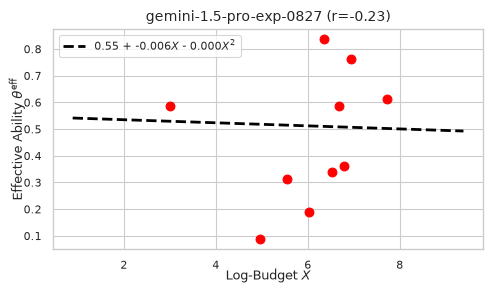

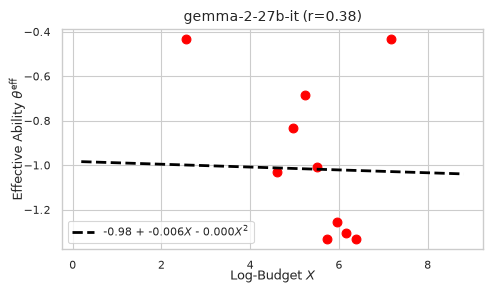

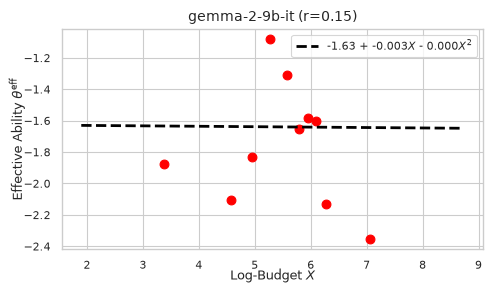

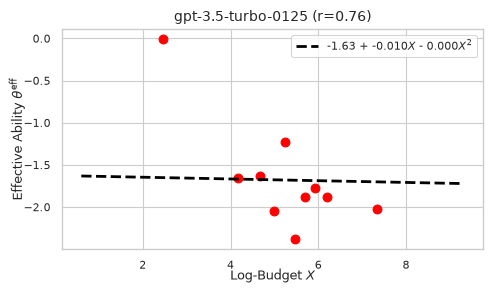

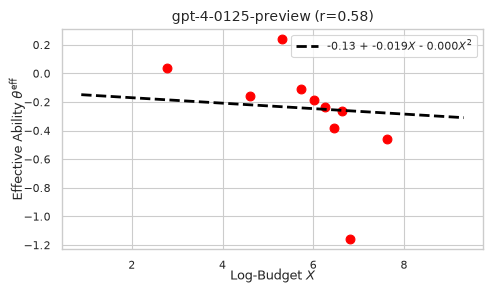

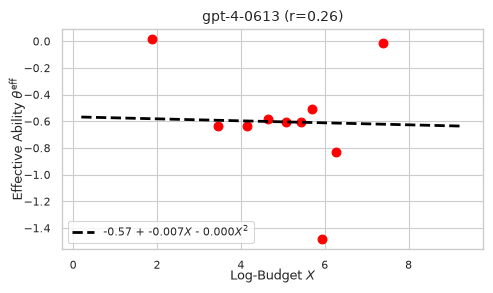

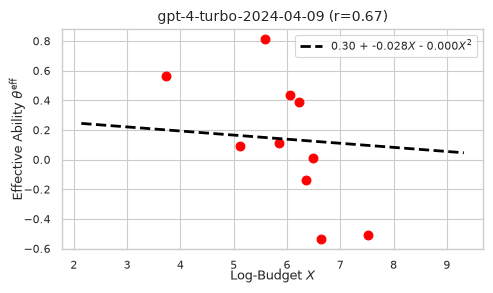

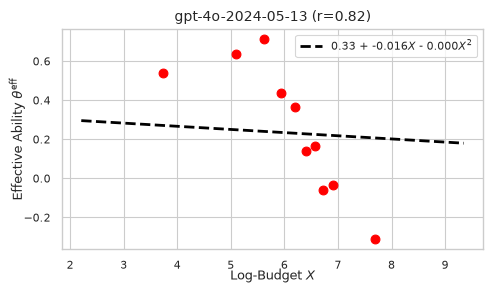

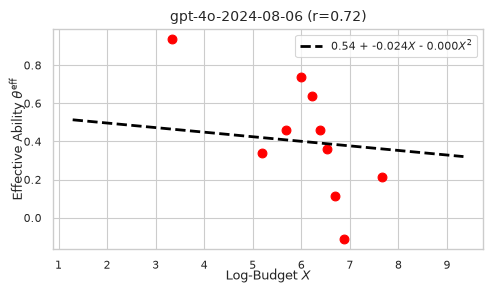

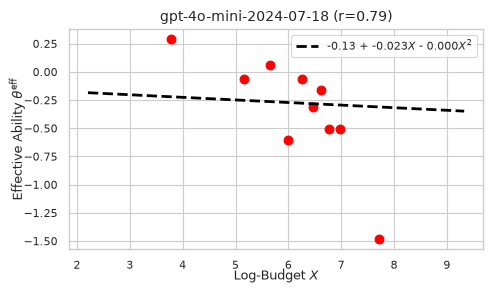

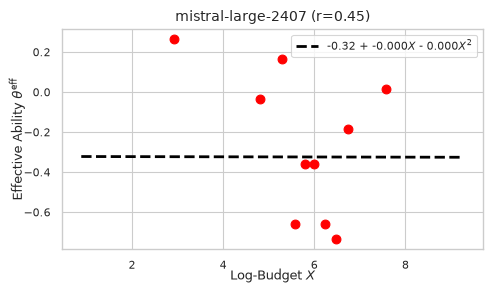

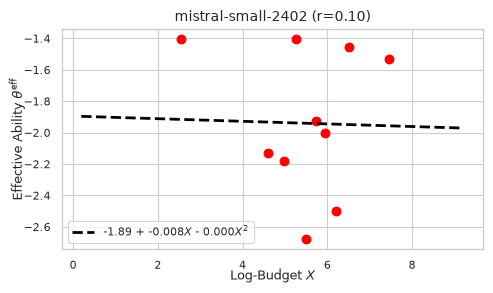

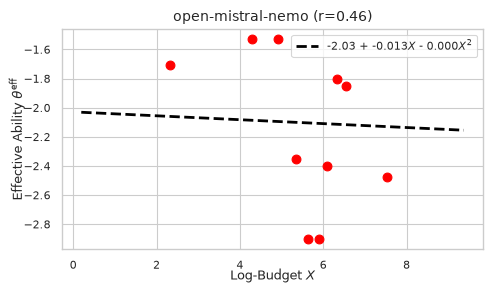

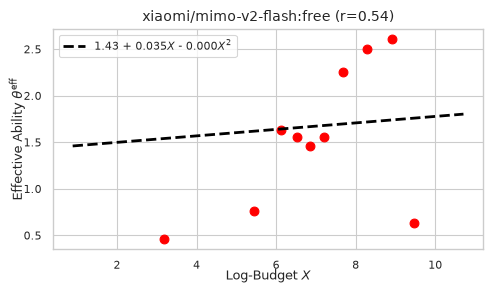

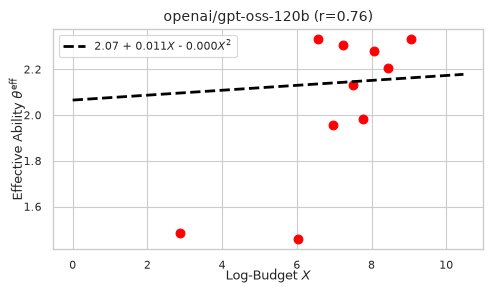

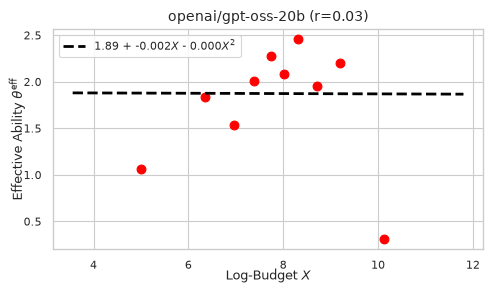

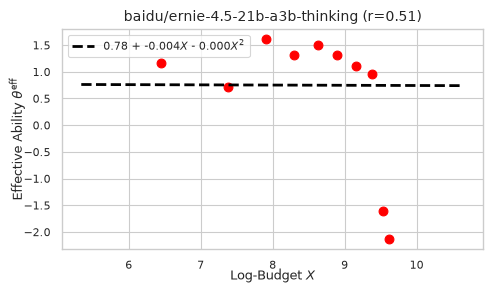

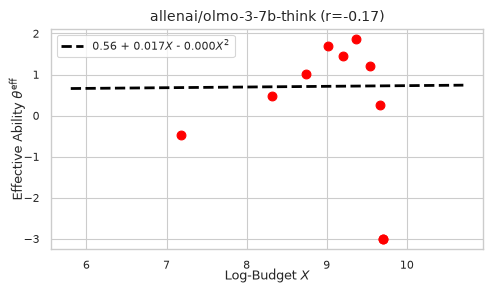

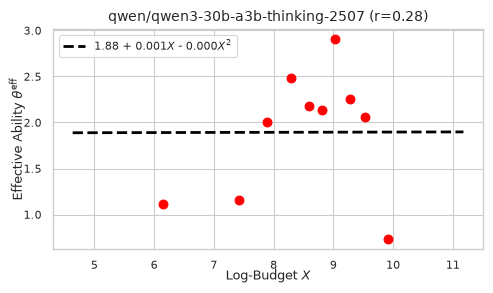

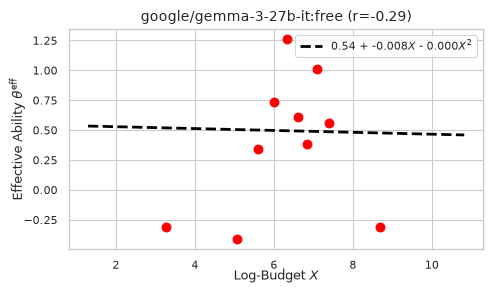

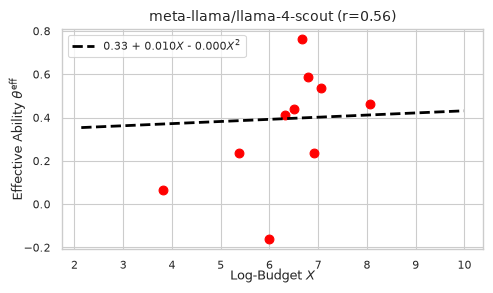

In [ ]:
from reasoning_aware_irt.utils import plot_empirical_bin_vs_3pl

res_list = []
for j in range(0,42):
    res = plot_empirical_bin_vs_3pl(
        x=B_ij[:,j], y=fit_results.b_i, 
        accuracy_np=Y_ij[:,j], accuracy_threshold=0.0, 
        apply_log_x=True,
        theta_base=fit_results.theta_j_mean[j],
        gamma=fit_results.gamma_j[j],  
        kappa=fit_results.kappa_j[j],  
        num_bins=10,
        color='red',
        connect_empirical=False,
        model_name=model_list[j],
        a_i=fit_results.a_i,
        c_i=fit_results.info['c_i'],
        theta_classic=theta_classic[j],
        show_linear_decline=True,
        save_path=None,
        # debug=True
    )
    res_list.append(res)

In [18]:
print(model_list[34])

xiaomi/mimo-v2-flash:free


In [24]:
# 10bins : all models
corr_list = [res_list[i]['corr'] for i in range(len(res_list))]
print(np.mean(corr_list))

0.31998035029862004


In [23]:
# 10bins : reasoning models only
corr_list = [res_list[i]['corr'] for i in range(34,len(res_list))]
print(np.mean(corr_list))

0.2778510967735238
